# 10 — Continued Pretraining (CPT)

## Terms & Definitions
- **Continued pretraining (CPT)**: taking an already-pretrained model and continuing the *same* next-token-prediction training objective, but on new/different text — rather than starting from random weights.
- **Domain adaptation**: shifting a model's learned distribution toward a specific domain, style, or vocabulary it will be used with later.
- **Catastrophic forgetting**: the risk that continuing to train on new data erases previously learned knowledge/behavior, especially if the learning rate is too high or training runs too long on narrow data.

## Why CPT Instead of Just Pretraining Longer, or Starting Over?
Our notebook 08 model already learned general English structure (spelling, common words, basic grammar) from *Electricity for Boys*. Suppose we now want the model to be especially fluent in a *narrower* domain — in our case, the short, templated instruction/response style used in `data/instruction_data.jsonl` (arithmetic, formatting, simple Q&A) — before we teach it to actually follow instructions in notebook 11.

CPT lets us:
1. **Reuse general knowledge** already learned during full pretraining, instead of re-learning basic English from scratch.
2. **Shift the model's "style"** toward the new domain's vocabulary and structure.
3. **Warm up** for SFT — SFT (next notebook) also trains on this same instruction data, but with a crucial difference (loss masking on the prompt). CPT here trains on the instruction data as plain unlabeled text (no masking), just to familiarize the model with this new distribution's raw *language* before SFT teaches it the *format*.

In production LLM pipelines, CPT is commonly used for things like adapting a general-purpose model to a specific language, a specific domain (legal, medical, code), or a company's internal documents — always with the same underlying mechanism: keep training with the next-token objective, just on new data, usually with a smaller/gentler learning rate than the original pretraining used.

## Key Practical Difference from Notebook 08: A Smaller Learning Rate
Because the model already has useful weights, CPT typically uses a **lower peak learning rate** than pretraining-from-scratch used. Too high a learning rate at this stage risks catastrophic forgetting — overwriting the general knowledge gained during pretraining with an overly aggressive fit to the new, narrower data. We'll use roughly 1/3 of notebook 08's peak LR.


In [1]:
import sys
sys.path.insert(0, "..")

import json
import time
import torch

from src.model import GPTMicro, GPTConfig
from src.data import train_bpe_tokenizer, load_electricity_for_boys, get_batch, get_train_val_split, set_seed
from src.train_utils import get_lr, estimate_loss, save_checkpoint, load_checkpoint, plot_losses

torch.set_num_threads(6)
set_seed(1337)


## Load the Pretrained Checkpoint


In [2]:
config = GPTConfig(vocab_size=8000, block_size=128, n_layer=6, n_head=8, n_embd=480, dropout=0.1)
model = GPTMicro(config)
load_checkpoint(model, "pretrained_electricity", device="cpu")
print(f"loaded pretrained_electricity checkpoint ({model.num_params()/1e6:.2f}M params)")

# Reuse the exact same tokenizer as pretraining -- CPT must use the same
# vocabulary the model was originally trained with.
text = load_electricity_for_boys()
tokenizer = train_bpe_tokenizer(text, vocab_size=8000)


loaded pretrained_electricity checkpoint (20.53M params)





## Prepare the CPT Corpus

For CPT we treat the *text* of the instruction dataset as plain unlabeled text -- concatenating every instruction and response together, ignoring the instruction/response boundary entirely (that structure only matters starting in notebook 11's SFT stage).


In [3]:
examples = [json.loads(line) for line in open("../data/instruction_data.jsonl")]
cpt_text = "\n".join(f"{ex['instruction']} {ex['response']}" for ex in examples)
print(f"CPT corpus: {len(cpt_text):,} characters from {len(examples)} instruction/response pairs")
print()
print(cpt_text[:300])


CPT corpus: 56,664 characters from 1000 instruction/response pairs

Convert 'current' to title case. Current
Convert 'energy' to title case. Energy
What is 44 + 12? 56
Convert 'current' to title case. Current
What is the purpose of a switchboard? A switchboard is used to control and distribute electric current to different circuits.
Convert 'workshop' to title case.


In [4]:
cpt_ids = tokenizer.encode(cpt_text).ids
cpt_data = torch.tensor(cpt_ids, dtype=torch.long)
cpt_train, cpt_val = get_train_val_split(cpt_data, val_fraction=0.1)
print(f"CPT corpus tokens: {len(cpt_data):,}  (train: {len(cpt_train):,}, val: {len(cpt_val):,})")


CPT corpus tokens: 15,437  (train: 13,893, val: 1,544)


## Continued Pretraining Loop

Notice this is *exactly* the same loop as notebook 08 -- same objective, same `get_batch`/`model(...)` calls -- the only differences are: we start from the pretrained checkpoint instead of random weights, we train on `cpt_train` instead of the original corpus, and we use a lower peak learning rate.


In [5]:
batch_size = 16
n_steps = 150
warmup_steps = 15
max_lr = 1e-4     # lower than notebook 08's 3e-4 -- gentler updates to avoid forgetting
eval_every = 30
eval_iters = 10

optimizer = torch.optim.AdamW(model.parameters(), lr=max_lr, weight_decay=0.01)

train_losses, val_losses = [], []
t0 = time.time()
for step in range(n_steps):
    lr = get_lr(step, warmup_steps, n_steps, max_lr)
    for g in optimizer.param_groups:
        g["lr"] = lr

    x, y = get_batch(cpt_train, config.block_size, batch_size, device="cpu")
    logits, loss = model(x, targets=y)

    optimizer.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    optimizer.step()

    train_losses.append(loss.item())
    if step % eval_every == 0 or step == n_steps - 1:
        val_loss = estimate_loss(model, cpt_val, config.block_size, batch_size, "cpu", eval_iters, get_batch)
        val_losses.append(val_loss)
        print(f"step {step:4d}/{n_steps}  train_loss {loss.item():.3f}  val_loss {val_loss:.3f}  ({time.time()-t0:.0f}s elapsed)")

print(f"\nCPT complete in {time.time()-t0:.0f}s")


step    0/150  train_loss 7.684  val_loss 7.643  (4s elapsed)
step   30/150  train_loss 4.245  val_loss 4.054  (38s elapsed)
step   60/150  train_loss 2.765  val_loss 2.547  (70s elapsed)
step   90/150  train_loss 1.996  val_loss 1.859  (103s elapsed)
step  120/150  train_loss 1.636  val_loss 1.632  (139s elapsed)
step  149/150  train_loss 1.584  val_loss 1.512  (172s elapsed)

CPT complete in 172s


step   30/150  train_loss 4.245  val_loss 4.054  (40s elapsed)


step   60/150  train_loss 2.765  val_loss 2.547  (74s elapsed)


step   90/150  train_loss 1.996  val_loss 1.859  (108s elapsed)


step  120/150  train_loss 1.636  val_loss 1.632  (147s elapsed)


step  149/150  train_loss 1.584  val_loss 1.512  (182s elapsed)

CPT complete in 182s


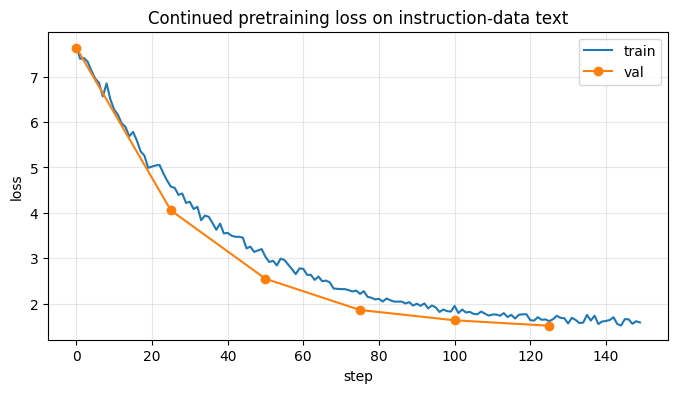

In [6]:
plot_losses(train_losses, val_losses, title="Continued pretraining loss on instruction-data text")


In [7]:
path = save_checkpoint(model, "cpt_electricity")
print(f"saved checkpoint to {path}")


saved checkpoint to /home/tyrel/projects/llm-lessons/checkpoints/cpt_electricity.pt


## Compare Before/After CPT Generations

Let's compare how the model completes a prompt drawn from the CPT domain's style, before vs. after this stage. (The "before" model is reloaded fresh from the pretrained checkpoint so the comparison is apples-to-apples.)


In [8]:
pretrained_model = GPTMicro(config)
load_checkpoint(pretrained_model, "pretrained_electricity", device="cpu")
pretrained_model.eval()
model.eval()

prompt = "What is a battery"
context = torch.tensor([tokenizer.encode(prompt).ids], dtype=torch.long)

torch.manual_seed(7)
before = pretrained_model.generate(context, max_new_tokens=30, temperature=0.8, top_k=40)
torch.manual_seed(7)
after = model.generate(context, max_new_tokens=30, temperature=0.8, top_k=40)

print("BEFORE CPT (pretrained_electricity):")
print(tokenizer.decode(before[0].tolist()))
print()
print("AFTER CPT (cpt_electricity):")
print(tokenizer.decode(after[0].tolist()))


BEFORE CPT (pretrained_electricity):
What is a battery, which is
In the other wire (D) are the wire (A) and one side of the terminal of an
It is an binding

AFTER CPT (cpt_electricity):
What is a battery used to flow through it.
What is 17  38? 9? A magnetic field when electric currents.
Convert 'ence' to


The "after" model should show some pull toward the shorter, more direct style of the instruction data (question-like prompts, terser continuations), even though it hasn't yet learned to actually *answer* in the instruction/response format -- that's specifically what SFT (next notebook) teaches, via loss masking that the plain-text CPT objective here doesn't use.

## Exercise
Try reducing `max_lr` further (e.g. to `3e-5`) and re-running -- notice CPT still makes some progress, just more slowly per step, illustrating the "gentler updates, less forgetting risk" tradeoff described above.

## Summary
- CPT continues the *same* next-token-prediction objective from a pretrained checkpoint, on new/adjacent text, instead of training from scratch.
- It's commonly used for domain adaptation in real LLM pipelines, and here we use it to warm the model up toward the instruction dataset's style before SFT.
- A lower learning rate than full pretraining is standard practice, to avoid catastrophic forgetting of previously learned knowledge.
- We saved this stage's result as the `cpt_electricity` checkpoint.

Next: **11 — Supervised Fine-Tuning (SFT)** (teach the model to actually follow the instruction/response format, using loss masking).
